In [ ]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna

from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder

import xgboost as xgb

from optuna.visualization import plot_optimization_history

<h2>Methods</h2>

- method to optimize df datatypes
- Optuna objective function

In [ ]:
# method to automatically downcast data types for a df
def optimize_dataframe_dtypes(df):
    df_opt = df.copy()

    for col in df_opt.columns:
        if col.startswith(("cat__", "encoded__")):
            # One-hot encoded -> int8
            df_opt[col] = df_opt[col].round().astype(np.int8)

        elif col.startswith("num__"):
            if pd.api.types.is_integer_dtype(df_opt[col]):
                df_opt[col] = pd.to_numeric(df_opt[col], downcast="integer")
            elif pd.api.types.is_float_dtype(df_opt[col]):
                df_opt[col] = pd.to_numeric(df_opt[col], downcast="float")

    return df_opt

In [ ]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "device": "cuda", # use gpu
}

In [ ]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "device": "cuda"
        }

    # Evaluate using a 3-fold TimeSeriesSplit
    tscv = TimeSeriesSplit(n_splits=3)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}

        # Train a model with up to 500 boosting rounds, early stopping if no improvement after 20 rounds
        # (it makes sense to treat num_boost_round separately, since xgb is iterative)
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=500,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, 
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration) # save the best boosting round
        # Get RMSE of the best iteration from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")
    
    # Save average values as performance indicators for Optuna
    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # Manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately as the performance indicator)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


<h1>Model-building</h1>

- for each state, we preprocess the data and optimize an NOx model with 20 Optuna trials and evaluate it by training with 2019-2023 data and testing on 2024 data five separate times and taking the average performance
- for NY, we additionally evaluate using year-by-year, rolling window, and static prediction horizon methods + we build models with and without lags for NOx, CO2, and SO2

In [ ]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

<h2>NY</h2>

<h3>No Lags</h3>

<h4>NOx</h4>

<h5>Preprocessing</h5>

In [ ]:
campd_df = pd.read_csv("Data/NY/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
# features
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols 

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [8]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [11]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [ ]:
study = optuna.create_study(
    study_name="30_07_00_20_XGB_NY_NOx",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)


[I 2025-07-31 16:55:51,507] A new study created in RDB with name: 30_07_00_20_XGB_NY_NOx


Starting trial 0
Fold 1 rmse: 12.4322 best_iteration: 17
Fold 2 rmse: 16.1708 best_iteration: 21


[I 2025-07-31 16:56:02,237] Trial 0 finished with value: 13.914284427589855 and parameters: {'max_depth': 11, 'learning_rate': 0.21297548855566956, 'subsample': 0.8476328139765199, 'colsample_bytree': 0.7431090327229245, 'gamma': 0.3231516199156928, 'reg_alpha': 0.10382810472335612, 'reg_lambda': 2.9206321365874133, 'min_child_weight': 14}. Best is trial 0 with value: 13.914284427589855.


Fold 3 rmse: 13.1398 best_iteration: 40
Trial 0 avg RMSE: 13.9143, avg best_iteration: 26
Starting trial 1
Fold 1 rmse: 13.2527 best_iteration: 168
Fold 2 rmse: 15.7585 best_iteration: 188


[I 2025-07-31 16:56:14,394] Trial 1 finished with value: 14.055407943163933 and parameters: {'max_depth': 5, 'learning_rate': 0.09592906389773714, 'subsample': 0.7047219756681442, 'colsample_bytree': 0.9767447161954066, 'gamma': 0.14492117322032189, 'reg_alpha': 0.021319006522948627, 'reg_lambda': 3.517332780287296, 'min_child_weight': 1}. Best is trial 0 with value: 13.914284427589855.


Fold 3 rmse: 13.1550 best_iteration: 170
Trial 1 avg RMSE: 14.0554, avg best_iteration: 175
Starting trial 2
Fold 1 rmse: 12.6696 best_iteration: 50
Fold 2 rmse: 15.8979 best_iteration: 81


... (32 outputs left out)

[I 2025-07-31 17:05:53,182] Trial 18 finished with value: 13.535454093712701 and parameters: {'max_depth': 14, 'learning_rate': 0.03862988406563438, 'subsample': 0.3900570639245221, 'colsample_bytree': 0.8416870210325514, 'gamma': 0.05484045248276443, 'reg_alpha': 0.1296669715196314, 'reg_lambda': 2.401091985962082, 'min_child_weight': 13}. Best is trial 11 with value: 13.498399252735888.


Fold 3 rmse: 12.8458 best_iteration: 140
Trial 18 avg RMSE: 13.5355, avg best_iteration: 154
Starting trial 19
Fold 1 rmse: 12.1658 best_iteration: 100
Fold 2 rmse: 15.4114 best_iteration: 158


[I 2025-07-31 17:06:12,862] Trial 19 finished with value: 13.501548943386434 and parameters: {'max_depth': 14, 'learning_rate': 0.046187851427709675, 'subsample': 0.5541332783068057, 'colsample_bytree': 0.7682073181905276, 'gamma': 0.1879185858316787, 'reg_alpha': 0.1292635551728023, 'reg_lambda': 2.659606975313587, 'min_child_weight': 15}. Best is trial 11 with value: 13.498399252735888.


Fold 3 rmse: 12.9275 best_iteration: 131
Trial 19 avg RMSE: 13.5015, avg best_iteration: 129
Best trial:
{'max_depth': 17, 'learning_rate': 0.014132101698009304, 'subsample': 0.36149745072437806, 'colsample_bytree': 0.8668299295657909, 'gamma': 0.056245908070831185, 'reg_alpha': 0.1918517126033973, 'reg_lambda': 1.6998567629520416, 'min_child_weight': 12}


In [18]:
study = optuna.load_study(
    study_name="30_07_00_20_XGB_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)

In [ ]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 380
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    'device': 'cuda'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 17, 'learning_rate': 0.014132101698009304, 'subsample': 0.36149745072437806, 'colsample_bytree': 0.8668299295657909, 'gamma': 0.056245908070831185, 'reg_alpha': 0.1918517126033973, 'reg_lambda': 1.6998567629520416, 'min_child_weight': 12}
Best value (RMSE): 13.498399252735888
380


<h5>Evaluation</h5>

In [ ]:
best_mse = np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **study.best_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'device': 'cuda',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=380
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.9714 | MSE: 105.4401 | RMSE: 10.2684 | nRMSE: 0.1693

Training iteration 2
R²: 0.9708 | MSE: 107.6160 | RMSE: 10.3738 | nRMSE: 0.1710

Training iteration 3
R²: 0.9710 | MSE: 106.7523 | RMSE: 10.3321 | nRMSE: 0.1703

Training iteration 4
R²: 0.9709 | MSE: 107.1028 | RMSE: 10.3490 | nRMSE: 0.1706

Training iteration 5
R²: 0.9710 | MSE: 106.8970 | RMSE: 10.3391 | nRMSE: 0.1704


In [2]:
r2_scores   = np.array([0.9714, 0.9708, 0.9710, 0.9709, 0.9710])
mse_values  = np.array([105.4401, 107.6160, 106.7523, 107.1028, 106.8970])
rmse_values = np.array([10.2684, 10.3738, 10.3321, 10.3490, 10.3391])
nrmse_values= np.array([0.1693, 0.1710, 0.1703, 0.1706, 0.1704])

avg_r2     = np.mean(r2_scores)
avg_mse    = np.mean(mse_values)
avg_rmse   = np.mean(rmse_values)
avg_nrmse  = np.mean(nrmse_values)

print(f"Average R2:     {avg_r2:.4f}")
print(f"Average MSE:    {avg_mse:.4f}")
print(f"Average RMSE:   {avg_rmse:.4f}")
print(f"Average nRMSE:  {avg_nrmse:.4f}")

Average R2:     0.9710
Average MSE:    106.7616
Average RMSE:   10.3325
Average nRMSE:  0.1703


R^2 Score: 0.9714
Mean Squared Error (MSE): 105.4401
Root Mean Squared Error (RMSE): 10.2684


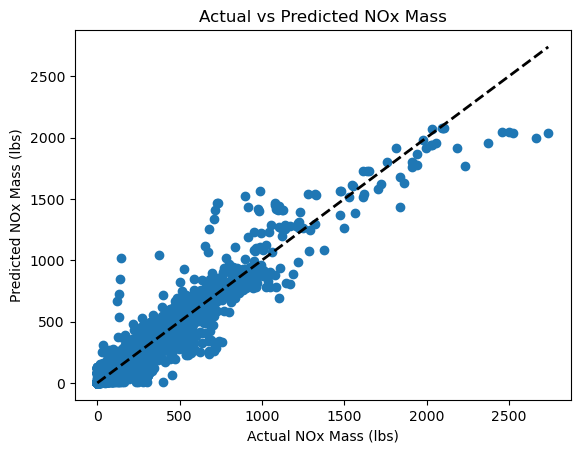

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_NY_NOx_No_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
model = xgb.Booster()
model.load_model("Trained Models/XGB_HPO_NY_NOx_No_Lags.json")

y_pred = model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

mask_below_500 = y_test < 500
mask_above_500 = y_test >= 500

print(f"RMSE for NOx Mass below 500 lbs: {np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500])):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500])) / np.std(y_test[mask_below_500]):.4f}")
print("")
print(f"RMSE for NOx Mass below 500 lbs: {np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500])):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500])) / np.std(y_test[mask_above_500]):.4f}")


RMSE for NOx Mass below 500 lbs: 8.2245
Normalized RMSE (by std): 0.2062

RMSE for NOx Mass below 500 lbs: 94.3687
Normalized RMSE (by std): 0.4446


In [ ]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=380)

    y_pred = model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9533, MSE: 167.8495, RMSE: 12.9557, nRMSE: 0.2163
Train: 2020, Test: 2021 | R^2: 0.9313, MSE: 237.9324, RMSE: 15.4251, nRMSE: 0.2618
Train: 2021, Test: 2022 | R^2: 0.9338, MSE: 348.8901, RMSE: 18.6786, nRMSE: 0.2573
Train: 2022, Test: 2023 | R^2: 0.9576, MSE: 136.5531, RMSE: 11.6856, nRMSE: 0.2058
Train: 2023, Test: 2024 | R^2: 0.9674, MSE: 119.9298, RMSE: 10.9512, nRMSE: 0.1803


In [43]:
r2_list = [0.9533, 0.9313, 0.9338, 0.9576, 0.9674]
mse_list = [167.8495, 237.9324, 348.8901, 136.5531, 119.9298]
rmse_list = [12.9557, 15.4251, 18.6786, 11.6856, 10.9512]
nrmse_list = [0.2163, 0.2618, 0.2573, 0.2058, 0.1803]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9487
Mean MSE: 202.231
Mean RMSE: 13.9392
Mean nRMSE: 0.2243


In [ ]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=171)

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

Train: [2019], Test: 2020 | R^2: 0.9428, MSE: 205.6035, RMSE: 14.3389, nRMSE: 0.2394
Train: [2019, 2020], Test: 2021 | R^2: 0.9315, MSE: 237.1103, RMSE: 15.3984, nRMSE: 0.2613
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9373, MSE: 330.6443, RMSE: 18.1836, nRMSE: 0.2505
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9580, MSE: 135.1838, RMSE: 11.6269, nRMSE: 0.2047
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9638, MSE: 133.4057, RMSE: 11.5501, nRMSE: 0.1902


In [44]:
r2_list = [0.9428, 0.9315, 0.9373, 0.9580, 0.9638]
mse_list = [205.6035, 237.1103, 330.6443, 135.1838, 133.4057]
rmse_list = [14.3389, 15.3984, 18.1836, 11.6269, 11.5501]
nrmse_list = [0.2394, 0.2613, 0.2505, 0.2047, 0.1902]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9467
Mean MSE: 208.3895
Mean RMSE: 14.2196
Mean nRMSE: 0.2292


In [ ]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=171)

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

Train: [2019], Test: 2024 | R^2: 0.9544, MSE: 167.8930, RMSE: 12.9574, nRMSE: 0.2134
Train: [2019, 2020], Test: 2024 | R^2: 0.9608, MSE: 144.2577, RMSE: 12.0107, nRMSE: 0.1978
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9595, MSE: 149.2304, RMSE: 12.2160, nRMSE: 0.2012
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9627, MSE: 137.3905, RMSE: 11.7214, nRMSE: 0.1930
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9638, MSE: 133.4057, RMSE: 11.5501, nRMSE: 0.1902


In [45]:
r2_list = [0.9544, 0.9608, 0.9595, 0.9627, 0.9638]
mse_list = [167.8930, 144.2577, 149.2304, 137.3905, 133.4057]
rmse_list = [12.9574, 12.0107, 12.2160, 11.7214, 11.5501]
nrmse_list = [0.2134, 0.1978, 0.2012, 0.1930, 0.1902]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9602
Mean MSE: 146.4355
Mean RMSE: 12.0911
Mean nRMSE: 0.1991


<h4>CO2</h4>

<h5>Preprocessing</h5>

In [4]:
campd_df = pd.read_csv("Data/NY/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
# features
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols 

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [8]:
study = optuna.create_study(
    study_name="31_07_20_45_XGB_NY_CO2",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)


[I 2025-07-31 18:50:00,416] A new study created in RDB with name: 31_07_20_45_XGB_NY_CO2


Starting trial 0
Fold 1 rmse: 1.9560 best_iteration: 40
Fold 2 rmse: 3.3286 best_iteration: 108


[I 2025-07-31 18:50:13,224] Trial 0 finished with value: 2.5419086593430547 and parameters: {'max_depth': 13, 'learning_rate': 0.19745267130141753, 'subsample': 0.5420539201763315, 'colsample_bytree': 0.9906330391877333, 'gamma': 0.44635278977686593, 'reg_alpha': 0.056982691762325045, 'reg_lambda': 4.389688017805894, 'min_child_weight': 10}. Best is trial 0 with value: 2.5419086593430547.


Fold 3 rmse: 2.3411 best_iteration: 28
Trial 0 avg RMSE: 2.5419, avg best_iteration: 58
Starting trial 1
Fold 1 rmse: 1.9238 best_iteration: 499
Fold 2 rmse: 3.4370 best_iteration: 499


[I 2025-07-31 18:52:27,595] Trial 1 finished with value: 2.542013487074607 and parameters: {'max_depth': 21, 'learning_rate': 0.01188082733183089, 'subsample': 0.9422903812377132, 'colsample_bytree': 0.7288739400728323, 'gamma': 0.22487940623267483, 'reg_alpha': 0.024558015270619717, 'reg_lambda': 5.217371327751285, 'min_child_weight': 15}. Best is trial 0 with value: 2.5419086593430547.


Fold 3 rmse: 2.2653 best_iteration: 499
Trial 1 avg RMSE: 2.5420, avg best_iteration: 499
Starting trial 2
Fold 1 rmse: 2.1066 best_iteration: 50
Fold 2 rmse: 3.4827 best_iteration: 72


... (32 outputs left out)

[I 2025-07-31 18:58:58,315] Trial 18 finished with value: 2.5136628422826224 and parameters: {'max_depth': 10, 'learning_rate': 0.03693164763309034, 'subsample': 0.555282198390914, 'colsample_bytree': 0.7000458563535376, 'gamma': 0.15456923068428297, 'reg_alpha': 0.11149319168296781, 'reg_lambda': 1.5872775052735837, 'min_child_weight': 5}. Best is trial 15 with value: 2.446575492680807.


Fold 3 rmse: 2.2358 best_iteration: 260
Trial 18 avg RMSE: 2.5137, avg best_iteration: 252
Starting trial 19
Fold 1 rmse: 2.0107 best_iteration: 249
Fold 2 rmse: 3.3879 best_iteration: 95


[I 2025-07-31 18:59:12,621] Trial 19 finished with value: 2.56753821423632 and parameters: {'max_depth': 7, 'learning_rate': 0.09855623141930472, 'subsample': 0.8484382233295965, 'colsample_bytree': 0.7573787442260379, 'gamma': 0.17242419223534713, 'reg_alpha': 0.0592420519424539, 'reg_lambda': 2.6944673714978262, 'min_child_weight': 3}. Best is trial 15 with value: 2.446575492680807.


Fold 3 rmse: 2.3040 best_iteration: 382
Trial 19 avg RMSE: 2.5675, avg best_iteration: 242
Best trial:
{'max_depth': 9, 'learning_rate': 0.023125830214620162, 'subsample': 0.6777921197186907, 'colsample_bytree': 0.8169143677900665, 'gamma': 0.017298854738142022, 'reg_alpha': 0.12574500835258712, 'reg_lambda': 2.7337692262495707, 'min_child_weight': 4}


In [ ]:
study = optuna.load_study(
    study_name="31_07_20_45_XGB_NY_CO2",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 399
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 9, 'learning_rate': 0.023125830214620162, 'subsample': 0.6777921197186907, 'colsample_bytree': 0.8169143677900665, 'gamma': 0.017298854738142022, 'reg_alpha': 0.12574500835258712, 'reg_lambda': 2.7337692262495707, 'min_child_weight': 4}
Best value (RMSE): 2.446575492680807
399


<h5>Evaluation</h5>

In [18]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'device': 'cuda',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=399
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.9993 | MSE: 2.1890 | RMSE: 1.4795 | nRMSE: 0.0267

Training iteration 2
R²: 0.9993 | MSE: 2.1171 | RMSE: 1.4550 | nRMSE: 0.0262

Training iteration 3
R²: 0.9993 | MSE: 2.1702 | RMSE: 1.4732 | nRMSE: 0.0266

Training iteration 4
R²: 0.9993 | MSE: 2.1597 | RMSE: 1.4696 | nRMSE: 0.0265

Training iteration 5
R²: 0.9993 | MSE: 2.2081 | RMSE: 1.4860 | nRMSE: 0.0268


In [3]:
r2_scores   = np.array([0.9993, 0.9993, 0.9993, 0.9993, 0.9993])
mse_values  = np.array([2.1890, 2.1171, 2.1702, 2.1597, 2.2081])
rmse_values = np.array([1.4795, 1.4550, 1.4732, 1.4696, 1.4860])
nrmse_values= np.array([0.0267, 0.0262, 0.0266, 0.0265, 0.0268])

avg_r2     = np.mean(r2_scores)
avg_mse    = np.mean(mse_values)
avg_rmse   = np.mean(rmse_values)
avg_nrmse  = np.mean(nrmse_values)

print(f"Average R2:     {avg_r2:.4f}")
print(f"Average MSE:    {avg_mse:.4f}")
print(f"Average RMSE:   {avg_rmse:.4f}")
print(f"Average nRMSE:  {avg_nrmse:.4f}")

Average R2:     0.9993
Average MSE:    2.1688
Average RMSE:   1.4727
Average nRMSE:  0.0266


R^2 Score: 0.9993
Mean Squared Error (MSE): 2.1171
Root Mean Squared Error (RMSE): 1.4550


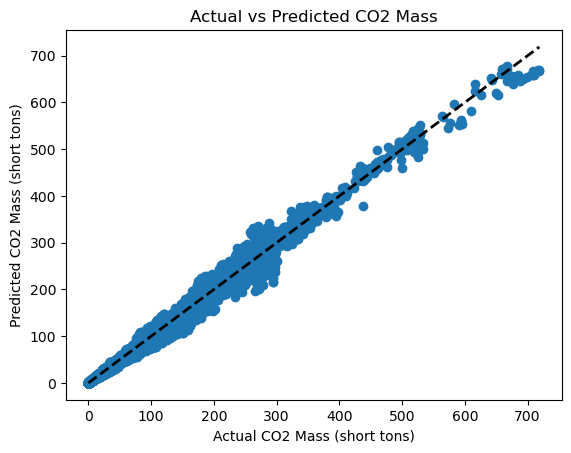

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_NY_CO2_No_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>SO2</h4>

<h5>Preprocessing</h5>

In [ ]:
campd_df = pd.read_csv("Data/NY/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols)

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [10]:
study = optuna.create_study(
    study_name="31_07_XX_XX_XGB_NY_SO2",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)


[I 2025-07-31 19:14:05,668] A new study created in RDB with name: 31_07_XX_XX_XGB_NY_SO2


Starting trial 0
Fold 1 rmse: 38.0742 best_iteration: 69
Fold 2 rmse: 69.9663 best_iteration: 34


[I 2025-07-31 19:14:15,550] Trial 0 finished with value: 48.77562492517995 and parameters: {'max_depth': 7, 'learning_rate': 0.19074217194680226, 'subsample': 0.4101521895646035, 'colsample_bytree': 0.741830244117671, 'gamma': 0.3759467899163328, 'reg_alpha': 0.15710061426929597, 'reg_lambda': 2.4456923957203194, 'min_child_weight': 1}. Best is trial 0 with value: 48.77562492517995.


Fold 3 rmse: 38.2864 best_iteration: 33
Trial 0 avg RMSE: 48.7756, avg best_iteration: 45
Starting trial 1
Fold 1 rmse: 38.4530 best_iteration: 88
Fold 2 rmse: 69.6891 best_iteration: 57


[I 2025-07-31 19:14:26,018] Trial 1 finished with value: 48.61964481549345 and parameters: {'max_depth': 4, 'learning_rate': 0.16358845235224398, 'subsample': 0.4467499685089757, 'colsample_bytree': 0.9962188522282475, 'gamma': 0.06197147152613991, 'reg_alpha': 0.13840450895516218, 'reg_lambda': 2.784742135981339, 'min_child_weight': 15}. Best is trial 1 with value: 48.61964481549345.


Fold 3 rmse: 37.7169 best_iteration: 149
Trial 1 avg RMSE: 48.6196, avg best_iteration: 98
Starting trial 2
Fold 1 rmse: 38.3295 best_iteration: 39
Fold 2 rmse: 69.2130 best_iteration: 153


... (32 outputs left out)

[I 2025-07-31 19:19:51,910] Trial 18 finished with value: 48.537647249233494 and parameters: {'max_depth': 20, 'learning_rate': 0.084112678419982, 'subsample': 0.7919150950548781, 'colsample_bytree': 0.8821093056588489, 'gamma': 0.10410640501095507, 'reg_alpha': 0.14865708241490855, 'reg_lambda': 1.9676407232323336, 'min_child_weight': 13}. Best is trial 6 with value: 47.313305859042934.


Fold 3 rmse: 39.9622 best_iteration: 112
Trial 18 avg RMSE: 48.5376, avg best_iteration: 117
Starting trial 19
Fold 1 rmse: 37.3303 best_iteration: 167
Fold 2 rmse: 68.2554 best_iteration: 268


[I 2025-07-31 19:20:06,472] Trial 19 finished with value: 47.96043655022779 and parameters: {'max_depth': 9, 'learning_rate': 0.03923284090953674, 'subsample': 0.6396886498763427, 'colsample_bytree': 0.9589413492268866, 'gamma': 0.21614962133145654, 'reg_alpha': 0.1760945921681174, 'reg_lambda': 5.982301593535549, 'min_child_weight': 5}. Best is trial 6 with value: 47.313305859042934.


Fold 3 rmse: 38.2956 best_iteration: 193
Trial 19 avg RMSE: 47.9604, avg best_iteration: 209
Best trial:
{'max_depth': 13, 'learning_rate': 0.039234847865245365, 'subsample': 0.5486048405291604, 'colsample_bytree': 0.976361245436852, 'gamma': 0.2259456187120698, 'reg_alpha': 0.17614210189656468, 'reg_lambda': 4.176731015232607, 'min_child_weight': 10}


In [ ]:
study = optuna.load_study(
    study_name="31_07_XX_XX_XGB_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 202
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 13, 'learning_rate': 0.039234847865245365, 'subsample': 0.5486048405291604, 'colsample_bytree': 0.976361245436852, 'gamma': 0.2259456187120698, 'reg_alpha': 0.17614210189656468, 'reg_lambda': 4.176731015232607, 'min_child_weight': 10}
Best value (RMSE): 47.313305859042934
202


<h5>Evaluation</h5>

In [9]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'device': 'cuda',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=202
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.8213 | MSE: 461.6466 | RMSE: 21.4860 | nRMSE: 0.4227

Training iteration 2
R²: 0.8149 | MSE: 478.2186 | RMSE: 21.8682 | nRMSE: 0.4302

Training iteration 3
R²: 0.8210 | MSE: 462.4738 | RMSE: 21.5052 | nRMSE: 0.4231

Training iteration 4
R²: 0.8184 | MSE: 469.2485 | RMSE: 21.6621 | nRMSE: 0.4261

Training iteration 5
R²: 0.8217 | MSE: 460.7607 | RMSE: 21.4653 | nRMSE: 0.4223


In [4]:
r2_scores   = np.array([0.8213, 0.8149, 0.8210, 0.8184, 0.8217])
mse_values  = np.array([461.6466, 478.2186, 462.4738, 469.2485, 460.7607])
rmse_values = np.array([21.4860, 21.8682, 21.5052, 21.6621, 21.4653])
nrmse_values= np.array([0.4227, 0.4302, 0.4231, 0.4261, 0.4223])

avg_r2     = np.mean(r2_scores)
avg_mse    = np.mean(mse_values)
avg_rmse   = np.mean(rmse_values)
avg_nrmse  = np.mean(nrmse_values)

print(f"Average R2:     {avg_r2:.4f}")
print(f"Average MSE:    {avg_mse:.4f}")
print(f"Average RMSE:   {avg_rmse:.4f}")
print(f"Average nRMSE:  {avg_nrmse:.4f}")

Average R2:     0.8195
Average MSE:    466.4696
Average RMSE:   21.5974
Average nRMSE:  0.4249


R^2 Score: 0.8217
Mean Squared Error (MSE): 460.7607
Root Mean Squared Error (RMSE): 21.4653


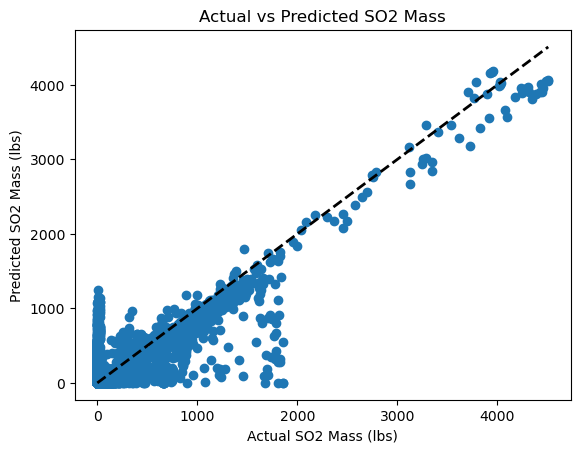

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_NY_SO2_No_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>With Lags</h3>

<h4>NOx</h4>

<h5>Preprocessing</h5>

In [ ]:
campd_df = pd.read_csv("Data/NY/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)# features

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols 

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [8]:
study = optuna.create_study(
    study_name="31_07_XX_XX_XGB_NY_NOx_With_Lags",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)


[I 2025-07-31 19:27:45,405] A new study created in RDB with name: 31_07_XX_XX_XGB_NY_NOx_With_Lags


Starting trial 0
Fold 1 rmse: 9.9961 best_iteration: 389
Fold 2 rmse: 10.8980 best_iteration: 357


[I 2025-07-31 19:28:02,417] Trial 0 finished with value: 10.388258968549568 and parameters: {'max_depth': 6, 'learning_rate': 0.03785598621225862, 'subsample': 0.3467678206792352, 'colsample_bytree': 0.9442904870156116, 'gamma': 0.2688184367800568, 'reg_alpha': 0.15199276488666402, 'reg_lambda': 3.702832394461701, 'min_child_weight': 9}. Best is trial 0 with value: 10.388258968549568.


Fold 3 rmse: 10.2707 best_iteration: 355
Trial 0 avg RMSE: 10.3883, avg best_iteration: 367
Starting trial 1
Fold 1 rmse: 11.3685 best_iteration: 16
Fold 2 rmse: 11.0112 best_iteration: 27


[I 2025-07-31 19:28:18,486] Trial 1 finished with value: 11.06732627125229 and parameters: {'max_depth': 18, 'learning_rate': 0.20138848340501353, 'subsample': 0.5877765241745655, 'colsample_bytree': 0.9084886281221427, 'gamma': 0.2970243534070082, 'reg_alpha': 0.029934251819393843, 'reg_lambda': 3.0887746020447557, 'min_child_weight': 10}. Best is trial 0 with value: 10.388258968549568.


Fold 3 rmse: 10.8223 best_iteration: 35
Trial 1 avg RMSE: 11.0673, avg best_iteration: 26
Starting trial 2
Fold 1 rmse: 9.7309 best_iteration: 25
Fold 2 rmse: 11.2521 best_iteration: 29


... (32 outputs left out)

[I 2025-07-31 19:39:55,967] Trial 18 finished with value: 10.159811462908777 and parameters: {'max_depth': 17, 'learning_rate': 0.05062443752002686, 'subsample': 0.6288130933393236, 'colsample_bytree': 0.8269511233733401, 'gamma': 0.35127670647082965, 'reg_alpha': 0.09663112566799892, 'reg_lambda': 2.3469354898520027, 'min_child_weight': 13}. Best is trial 12 with value: 10.119760111061266.


Fold 3 rmse: 10.1828 best_iteration: 128
Trial 18 avg RMSE: 10.1598, avg best_iteration: 127
Starting trial 19
Fold 1 rmse: 9.3706 best_iteration: 89
Fold 2 rmse: 11.1605 best_iteration: 63


[I 2025-07-31 19:40:11,400] Trial 19 finished with value: 10.26307745646546 and parameters: {'max_depth': 12, 'learning_rate': 0.09775493275678371, 'subsample': 0.8378231718032414, 'colsample_bytree': 0.7522063761660946, 'gamma': 0.43781185459728567, 'reg_alpha': 0.12803159520600427, 'reg_lambda': 3.464384402249337, 'min_child_weight': 15}. Best is trial 12 with value: 10.119760111061266.


Fold 3 rmse: 10.2581 best_iteration: 79
Trial 19 avg RMSE: 10.2631, avg best_iteration: 77
Best trial:
{'max_depth': 15, 'learning_rate': 0.012571918951808746, 'subsample': 0.762917076423065, 'colsample_bytree': 0.9952581063900602, 'gamma': 0.43057648873086946, 'reg_alpha': 0.09119648947432554, 'reg_lambda': 1.7546690083589211, 'min_child_weight': 12}


In [ ]:
study = optuna.load_study(
    study_name="31_07_XX_XX_XGB_NY_NOx_With_Lags",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 459
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 15, 'learning_rate': 0.012571918951808746, 'subsample': 0.762917076423065, 'colsample_bytree': 0.9952581063900602, 'gamma': 0.43057648873086946, 'reg_alpha': 0.09119648947432554, 'reg_lambda': 1.7546690083589211, 'min_child_weight': 12}
Best value (RMSE): 10.119760111061266
459


<h5>Evaluation</h5>

In [8]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'device': 'cuda',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=459
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.9821 | MSE: 65.7777 | RMSE: 8.1103 | nRMSE: 0.1337

Training iteration 2
R²: 0.9819 | MSE: 66.7316 | RMSE: 8.1689 | nRMSE: 0.1347

Training iteration 3
R²: 0.9817 | MSE: 67.1755 | RMSE: 8.1961 | nRMSE: 0.1351

Training iteration 4
R²: 0.9818 | MSE: 66.8543 | RMSE: 8.1764 | nRMSE: 0.1348

Training iteration 5
R²: 0.9817 | MSE: 67.4696 | RMSE: 8.2140 | nRMSE: 0.1354


In [9]:
r2_scores = np.array([0.9821, 0.9819, 0.9817, 0.9818, 0.9817])
mse_values = np.array([65.7777, 66.7316, 67.1755, 66.8543, 67.4696])
rmse_values = np.array([8.1103, 8.1689, 8.1961, 8.1764, 8.2140])
nrmse_values = np.array([0.1337, 0.1347, 0.1351, 0.1348, 0.1354])

print(f"R2: {np.mean(r2_scores):.3f}")
print(f"MSE: {np.mean(mse_values):.3f}")
print(f"RMSE: {np.mean(rmse_values):.3f}")
print(f"nRMSE: {np.mean(nrmse_values):.3f}")

R2: 0.982
MSE: 66.802
RMSE: 8.173
nRMSE: 0.135


R^2 Score: 0.9821
Mean Squared Error (MSE): 65.7777
Root Mean Squared Error (RMSE): 8.1103


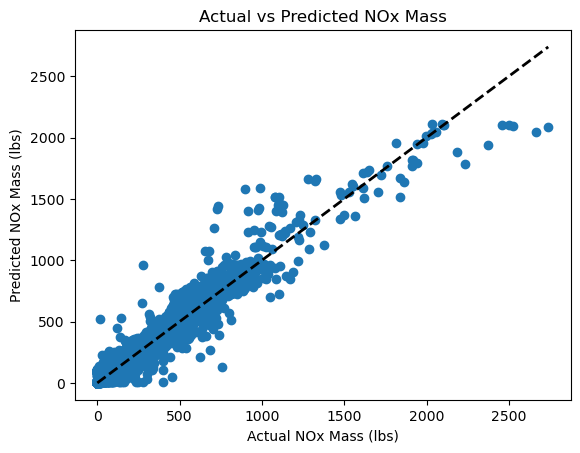

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_NY_NOx_With_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>CO2</h4>

<h5>Preprocessing</h5>

In [ ]:
campd_df = pd.read_csv("Data/NY/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)# features

In [ ]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols 

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [8]:
study = optuna.create_study(
    study_name="31_07_XX_XX_XGB_NY_CO2_With_Lags",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)


[I 2025-07-31 19:59:19,177] A new study created in RDB with name: 31_07_XX_XX_XGB_NY_CO2_With_Lags


Starting trial 0
Fold 1 rmse: 1.7090 best_iteration: 499
Fold 2 rmse: 2.9557 best_iteration: 499


[I 2025-07-31 19:59:35,244] Trial 0 finished with value: 2.156978739601785 and parameters: {'max_depth': 4, 'learning_rate': 0.09265286934877656, 'subsample': 0.4164955710828078, 'colsample_bytree': 0.8345342723190857, 'gamma': 0.1615326491747085, 'reg_alpha': 0.16995229121242217, 'reg_lambda': 4.769187667435822, 'min_child_weight': 13}. Best is trial 0 with value: 2.156978739601785.


Fold 3 rmse: 1.8062 best_iteration: 499
Trial 0 avg RMSE: 2.1570, avg best_iteration: 499
Starting trial 1
Fold 1 rmse: 1.4852 best_iteration: 282
Fold 2 rmse: 2.6298 best_iteration: 474


[I 2025-07-31 20:00:53,819] Trial 1 finished with value: 1.8813933587315983 and parameters: {'max_depth': 24, 'learning_rate': 0.03555442989372821, 'subsample': 0.45969249670842033, 'colsample_bytree': 0.8807498062354366, 'gamma': 0.18807155378421436, 'reg_alpha': 0.12294132052182141, 'reg_lambda': 2.5137750671970096, 'min_child_weight': 9}. Best is trial 1 with value: 1.8813933587315983.


Fold 3 rmse: 1.5292 best_iteration: 253
Trial 1 avg RMSE: 1.8814, avg best_iteration: 336
Starting trial 2
Fold 1 rmse: 1.8512 best_iteration: 135
Fold 2 rmse: 2.8101 best_iteration: 53


... (32 outputs left out)

[I 2025-07-31 20:10:18,453] Trial 18 finished with value: 1.9492583246472444 and parameters: {'max_depth': 21, 'learning_rate': 0.05061261638546652, 'subsample': 0.6757244672688071, 'colsample_bytree': 0.7118639966719766, 'gamma': 0.20505013775236508, 'reg_alpha': 0.10915426309679281, 'reg_lambda': 2.7908732346126213, 'min_child_weight': 14}. Best is trial 9 with value: 1.848054345087905.


Fold 3 rmse: 1.6308 best_iteration: 258
Trial 18 avg RMSE: 1.9493, avg best_iteration: 240
Starting trial 19
Fold 1 rmse: 1.5875 best_iteration: 101
Fold 2 rmse: 2.6593 best_iteration: 172


[I 2025-07-31 20:10:42,841] Trial 19 finished with value: 1.9637406420878316 and parameters: {'max_depth': 16, 'learning_rate': 0.10291913906325784, 'subsample': 0.5240698572894337, 'colsample_bytree': 0.8555809777877545, 'gamma': 0.07614703049409918, 'reg_alpha': 0.13851998876442406, 'reg_lambda': 2.0542954998837417, 'min_child_weight': 10}. Best is trial 9 with value: 1.848054345087905.


Fold 3 rmse: 1.6444 best_iteration: 184
Trial 19 avg RMSE: 1.9637, avg best_iteration: 152
Best trial:
{'max_depth': 9, 'learning_rate': 0.16244673906626098, 'subsample': 0.8762675062771006, 'colsample_bytree': 0.981562994781211, 'gamma': 0.08990040496721352, 'reg_alpha': 0.16562836447873316, 'reg_lambda': 4.747070632481047, 'min_child_weight': 14}


In [ ]:
study = optuna.load_study(
    study_name="31_07_XX_XX_XGB_NY_CO2_With_Lags",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 148
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 9, 'learning_rate': 0.16244673906626098, 'subsample': 0.8762675062771006, 'colsample_bytree': 0.981562994781211, 'gamma': 0.08990040496721352, 'reg_alpha': 0.16562836447873316, 'reg_lambda': 4.747070632481047, 'min_child_weight': 14}
Best value (RMSE): 1.848054345087905
148


<h5>Evaluation</h5>

In [8]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'device': 'cuda',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=148
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.9996 | MSE: 1.2859 | RMSE: 1.1340 | nRMSE: 0.0204

Training iteration 2
R²: 0.9996 | MSE: 1.2310 | RMSE: 1.1095 | nRMSE: 0.0200

Training iteration 3
R²: 0.9996 | MSE: 1.2488 | RMSE: 1.1175 | nRMSE: 0.0201

Training iteration 4
R²: 0.9996 | MSE: 1.2745 | RMSE: 1.1289 | nRMSE: 0.0204

Training iteration 5
R²: 0.9996 | MSE: 1.2688 | RMSE: 1.1264 | nRMSE: 0.0203


In [12]:
r2_scores = np.array([0.9996, 0.9996, 0.9996, 0.9996, 0.9996])
mse_values = np.array([1.2859, 1.2310, 1.2488, 1.2745, 1.2688])
rmse_values = np.array([1.1340, 1.1095, 1.1175, 1.1289, 1.1264])
nrmse_values = np.array([0.0204, 0.0200, 0.0201, 0.0204, 0.0203])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

R2: 0.9996
MSE: 1.2618
RMSE: 1.1233
nRMSE: 0.0202


R^2 Score: 0.9996
Mean Squared Error (MSE): 1.2310
Root Mean Squared Error (RMSE): 1.1095


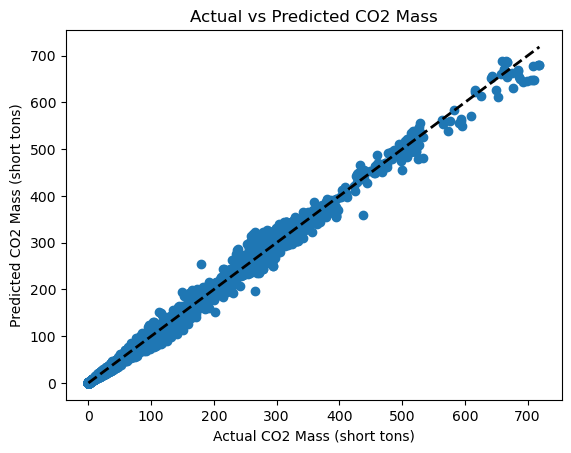

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_NY_CO2_With_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>SO2</h4>

<h5>Preprocessing</h5>

In [4]:
campd_df = pd.read_csv("Data/NY/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
# features
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols)

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [8]:
study = optuna.create_study(
    study_name="01_08_16_30_XGB_NY_SO2",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

[I 2025-08-01 14:28:22,255] A new study created in RDB with name: 01_08_16_30_XGB_NY_SO2


Starting trial 0
Fold 1 rmse: 16.1771 best_iteration: 22
Fold 2 rmse: 29.4566 best_iteration: 26


[I 2025-08-01 14:28:35,770] Trial 0 finished with value: 20.23107022571634 and parameters: {'max_depth': 22, 'learning_rate': 0.17128038145706106, 'subsample': 0.9578648782755521, 'colsample_bytree': 0.9501633695676028, 'gamma': 0.31951504745508175, 'reg_alpha': 0.14441924744045873, 'reg_lambda': 0.8751311407775795, 'min_child_weight': 13}. Best is trial 0 with value: 20.23107022571634.


Fold 3 rmse: 15.0596 best_iteration: 25
Trial 0 avg RMSE: 20.2311, avg best_iteration: 24
Starting trial 1
Fold 1 rmse: 16.8136 best_iteration: 54
Fold 2 rmse: 30.9195 best_iteration: 68


[I 2025-08-01 14:28:46,842] Trial 1 finished with value: 20.096628752286236 and parameters: {'max_depth': 8, 'learning_rate': 0.07760016936604151, 'subsample': 0.4189523249007856, 'colsample_bytree': 0.8022063592837165, 'gamma': 0.22065349983157456, 'reg_alpha': 0.10472709345374848, 'reg_lambda': 0.49632576440728926, 'min_child_weight': 10}. Best is trial 1 with value: 20.096628752286236.


Fold 3 rmse: 12.5568 best_iteration: 71
Trial 1 avg RMSE: 20.0966, avg best_iteration: 64
Starting trial 2
Fold 1 rmse: 15.4942 best_iteration: 20
Fold 2 rmse: 29.8079 best_iteration: 31


... (32 outputs left out)

[I 2025-08-01 14:33:22,893] Trial 18 finished with value: 19.799757672815094 and parameters: {'max_depth': 8, 'learning_rate': 0.19257431956439175, 'subsample': 0.46202294307314773, 'colsample_bytree': 0.7068434671239351, 'gamma': 0.1872988312210702, 'reg_alpha': 0.10888144463980248, 'reg_lambda': 4.000398002679512, 'min_child_weight': 5}. Best is trial 9 with value: 19.15138531292492.


Fold 3 rmse: 12.7993 best_iteration: 27
Trial 18 avg RMSE: 19.7998, avg best_iteration: 71
Starting trial 19
Fold 1 rmse: 15.0622 best_iteration: 61
Fold 2 rmse: 27.7324 best_iteration: 29


[I 2025-08-01 14:33:34,504] Trial 19 finished with value: 18.77197486935678 and parameters: {'max_depth': 6, 'learning_rate': 0.14457694891177442, 'subsample': 0.6343414000701337, 'colsample_bytree': 0.8010742211355857, 'gamma': 0.32143470952821307, 'reg_alpha': 0.06520571502410402, 'reg_lambda': 1.7356970577047048, 'min_child_weight': 3}. Best is trial 19 with value: 18.77197486935678.


Fold 3 rmse: 13.5213 best_iteration: 36
Trial 19 avg RMSE: 18.7720, avg best_iteration: 42
Best trial:
{'max_depth': 6, 'learning_rate': 0.14457694891177442, 'subsample': 0.6343414000701337, 'colsample_bytree': 0.8010742211355857, 'gamma': 0.32143470952821307, 'reg_alpha': 0.06520571502410402, 'reg_lambda': 1.7356970577047048, 'min_child_weight': 3}


In [ ]:
study = optuna.load_study(
    study_name="01_08_16_30_XGB_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 42
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 6, 'learning_rate': 0.14457694891177442, 'subsample': 0.6343414000701337, 'colsample_bytree': 0.8010742211355857, 'gamma': 0.32143470952821307, 'reg_alpha': 0.06520571502410402, 'reg_lambda': 1.7356970577047048, 'min_child_weight': 3}
Best value (RMSE): 18.77197486935678
42


<h5>Evaluation</h5>

In [9]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'device': 'cuda',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=42
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.9543 | MSE: 118.0188 | RMSE: 10.8636 | nRMSE: 0.2137

Training iteration 2
R²: 0.9492 | MSE: 131.2914 | RMSE: 11.4582 | nRMSE: 0.2254

Training iteration 3
R²: 0.9542 | MSE: 118.2691 | RMSE: 10.8752 | nRMSE: 0.2139

Training iteration 4
R²: 0.9407 | MSE: 153.1898 | RMSE: 12.3770 | nRMSE: 0.2435

Training iteration 5
R²: 0.9503 | MSE: 128.5035 | RMSE: 11.3359 | nRMSE: 0.2230


In [13]:
r2_scores = np.array([0.9543, 0.9492, 0.9542, 0.9407, 0.9503])
mse_values = np.array([118.0188, 131.2914, 118.2691, 153.1898, 128.5035])
rmse_values = np.array([10.8636, 11.4582, 10.8752, 12.3770, 11.3359])
nrmse_values = np.array([0.2137, 0.2254, 0.2139, 0.2435, 0.2230])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

R2: 0.9497
MSE: 129.8545
RMSE: 11.3820
nRMSE: 0.2239


R^2 Score: 0.9543
Mean Squared Error (MSE): 118.0188
Root Mean Squared Error (RMSE): 10.8636


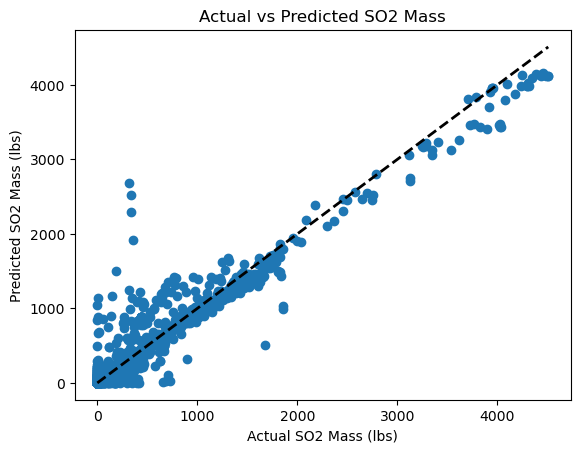

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_NY_SO2_With_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>WY</h2>

<h3>No Lags</h3>

<h4>NOx</h4>

<h5>Preprocessing</h5>

In [46]:
campd_df = pd.read_csv("Data/WY/wy_2019_2024_complete_cleaned_Full_manually_encoded.gz", dtype=campd_type_dict)

In [ ]:
# features
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols 

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [48]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [ ]:
study = optuna.create_study(
    study_name="01_08_00_20_XGB_WY_NOx",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [ ]:
study = optuna.load_study(
    study_name="01_08_00_20_XGB_WY_NOx",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 171
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    'device': 'cuda'
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 4, 'learning_rate': 0.07143299897235258, 'subsample': 0.5908110590402121, 'colsample_bytree': 0.9371694023131072, 'gamma': 0.31409245975861844, 'reg_alpha': 0.03512013407894932, 'reg_lambda': 1.1788576597310105, 'min_child_weight': 11}
Best value (RMSE): 52.734891590675154
171


<h5>Evaluation</h5>

In [15]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=171
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.8885 | MSE: 5172.3945 | RMSE: 71.9194 | nRMSE: 0.3339

Training iteration 2
R²: 0.8873 | MSE: 5229.2773 | RMSE: 72.3137 | nRMSE: 0.3357

Training iteration 3
R²: 0.8890 | MSE: 5148.1724 | RMSE: 71.7508 | nRMSE: 0.3331

Training iteration 4
R²: 0.8897 | MSE: 5119.6401 | RMSE: 71.5517 | nRMSE: 0.3322

Training iteration 5
R²: 0.8875 | MSE: 5218.3291 | RMSE: 72.2380 | nRMSE: 0.3354


R^2 Score: 0.8897
Mean Squared Error (MSE): 5119.6401
Root Mean Squared Error (RMSE): 71.5517


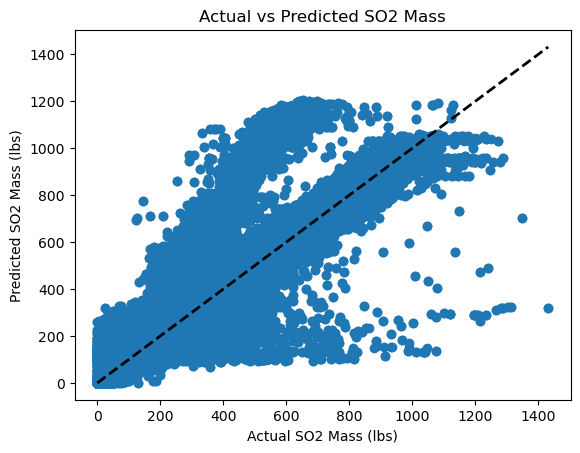

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_WY_NOx_No_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.8897
Mean Squared Error (MSE): 5119.6436
Root Mean Squared Error (RMSE): 71.5517


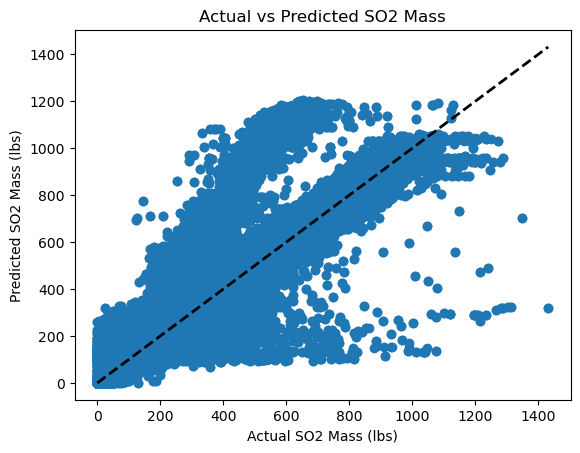

In [ ]:
model = xgb.Booster()
model.load_model("Trained Models/XGB_HPO_WY_NOx_No_Lags.json")

dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

y_pred = model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

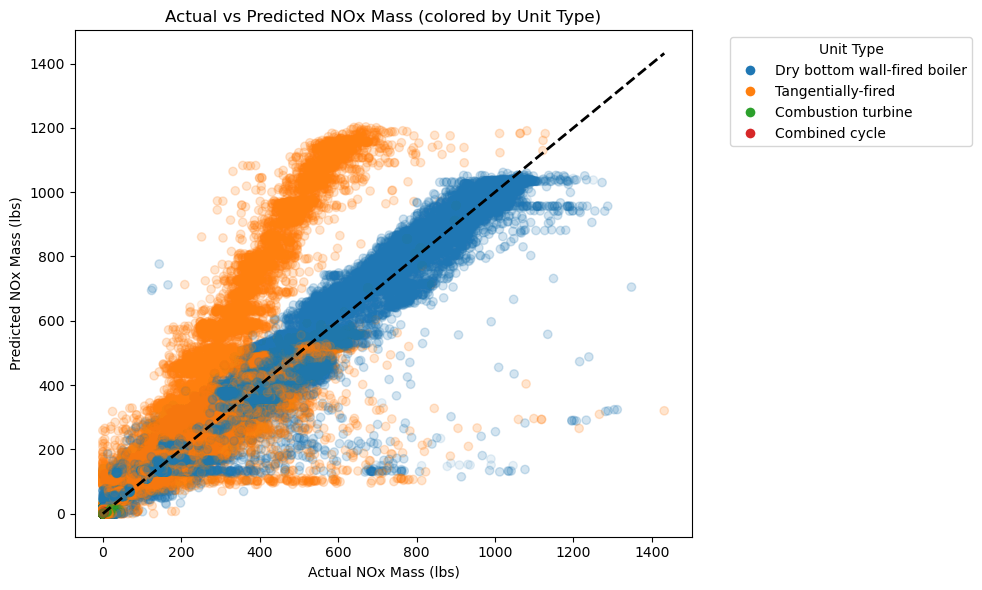

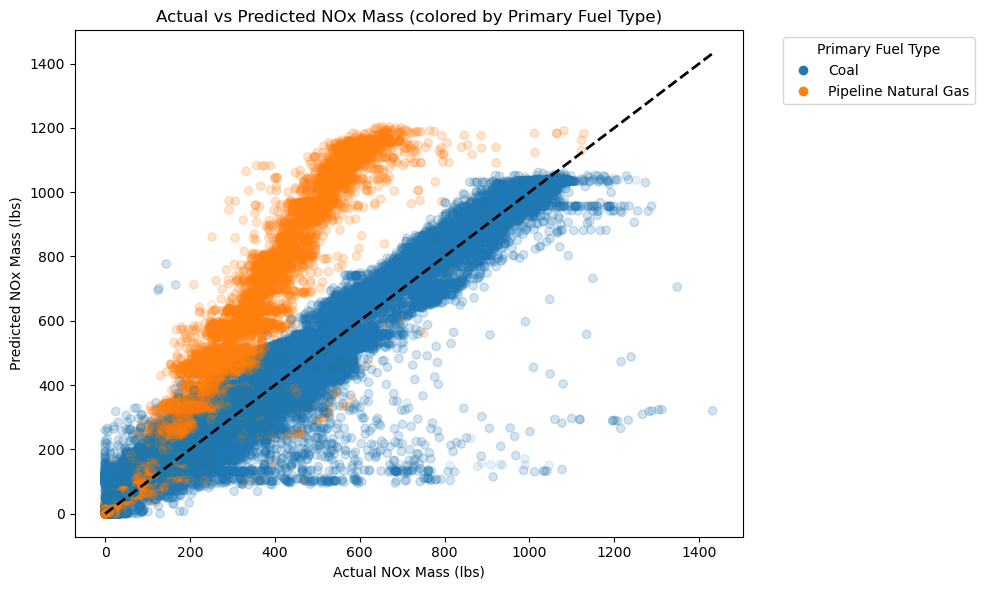

In [ ]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#####################################################

train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

fuel_types_test = campd_df.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()




In [ ]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=171)

    y_pred = model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9731, MSE: 1933.6654, RMSE: 43.9735, nRMSE: 0.1638
Train: 2020, Test: 2021 | R^2: 0.9727, MSE: 2000.0686, RMSE: 44.7221, nRMSE: 0.1653
Train: 2021, Test: 2022 | R^2: 0.9590, MSE: 3525.3484, RMSE: 59.3746, nRMSE: 0.2026
Train: 2022, Test: 2023 | R^2: 0.9543, MSE: 3216.7073, RMSE: 56.7160, nRMSE: 0.2138
Train: 2023, Test: 2024 | R^2: 0.8972, MSE: 4767.8203, RMSE: 69.0494, nRMSE: 0.3206


In [40]:
r2_list = [0.9731, 0.9727, 0.9590, 0.9543, 0.8972]
mse_list = [1933.6654, 2000.0686, 3525.3484, 3216.7073, 4767.8203]
rmse_list = [43.9735, 44.7221, 59.3746, 56.7160, 69.0494]
nrmse_list = [0.1638, 0.1653, 0.2026, 0.2138, 0.3206]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9513
Mean MSE: 3088.722
Mean RMSE: 54.7671
Mean nRMSE: 0.2132


In [ ]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=171)

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")



Train: [2019], Test: 2020 | R^2: 0.9731, MSE: 1933.6654, RMSE: 43.9735, nRMSE: 0.1638
Train: [2019, 2020], Test: 2021 | R^2: 0.9707, MSE: 2145.8113, RMSE: 46.3229, nRMSE: 0.1712
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9607, MSE: 3378.8086, RMSE: 58.1275, nRMSE: 0.1984
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9598, MSE: 2827.8940, RMSE: 53.1779, nRMSE: 0.2004
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.8885, MSE: 5172.3945, RMSE: 71.9194, nRMSE: 0.3339


In [41]:
r2_list = [0.9731, 0.9707, 0.9607, 0.9598, 0.8885]
mse_list = [1933.6654, 2145.8113, 3378.8086, 2827.8940, 5172.3945]
rmse_list = [43.9735, 46.3229, 58.1275, 53.1779, 71.9194]
nrmse_list = [0.1638, 0.1712, 0.1984, 0.2004, 0.3339]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9506
Mean MSE: 3091.7148
Mean RMSE: 54.7042
Mean nRMSE: 0.2135


In [ ]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=171)

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2024 | R^2: 0.7842, MSE: 10012.4355, RMSE: 100.0622, nRMSE: 0.4646
Train: [2019, 2020], Test: 2024 | R^2: 0.8403, MSE: 7408.4927, RMSE: 86.0726, nRMSE: 0.3997
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.8647, MSE: 6276.2808, RMSE: 79.2230, nRMSE: 0.3679
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.8622, MSE: 6392.2261, RMSE: 79.9514, nRMSE: 0.3712
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.8885, MSE: 5172.3945, RMSE: 71.9194, nRMSE: 0.3339


In [42]:
r2_list = [0.7842, 0.8403, 0.8647, 0.8622, 0.8885]
mse_list = [10012.4355, 7408.4927, 6276.2808, 6392.2261, 5172.3945]
rmse_list = [100.0622, 86.0726, 79.2230, 79.9514, 71.9194]
nrmse_list = [0.4646, 0.3997, 0.3679, 0.3712, 0.3339]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.848
Mean MSE: 7052.3659
Mean RMSE: 83.4457
Mean nRMSE: 0.3875


<h2>TX</h2>

<h3>No Lags</h3>

<h4>NOx</h4>

<h5>Preprocessing</h5>

In [20]:
campd_df = pd.read_csv("Data/TX/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured_super_compressed.gz", dtype=campd_type_dict)

In [ ]:
# features
df_control_cols = ['Ammonia Injection',
       'Combustion Modification/Fuel Reburning', 'Dry Low NOx Burners',
       'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols 

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [22]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

<h5>HPO</h5>

In [23]:
study = optuna.create_study(
    study_name="03_08_18_00_XGB_TX_NOx",
    storage="sqlite:///optuna_studies.db",
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

[I 2025-08-03 15:59:09,476] A new study created in RDB with name: 03_08_18_00_XGB_TX_NOx


Starting trial 0
Fold 1 rmse: 52.1651 best_iteration: 169
Fold 2 rmse: 46.5670 best_iteration: 97


[I 2025-08-03 15:59:18,252] Trial 0 finished with value: 49.50428911029559 and parameters: {'max_depth': 5, 'learning_rate': 0.21068991003997092, 'subsample': 0.6064791652020916, 'colsample_bytree': 0.8409841853369355, 'gamma': 0.20450812924684886, 'reg_alpha': 0.06431972716462002, 'reg_lambda': 3.6235437880565797, 'min_child_weight': 6}. Best is trial 0 with value: 49.50428911029559.


Fold 3 rmse: 49.7808 best_iteration: 103
Trial 0 avg RMSE: 49.5043, avg best_iteration: 123
Starting trial 1
Fold 1 rmse: 52.4716 best_iteration: 195
Fold 2 rmse: 47.9269 best_iteration: 189


[I 2025-08-03 16:00:24,665] Trial 1 finished with value: 49.736755115783325 and parameters: {'max_depth': 16, 'learning_rate': 0.025417817987751227, 'subsample': 0.811222923027701, 'colsample_bytree': 0.7790966727002703, 'gamma': 0.35777763887176756, 'reg_alpha': 0.09517267877492142, 'reg_lambda': 0.13256812190389433, 'min_child_weight': 5}. Best is trial 0 with value: 49.50428911029559.


Fold 3 rmse: 48.8118 best_iteration: 158
Trial 1 avg RMSE: 49.7368, avg best_iteration: 180
Starting trial 2
Fold 1 rmse: 53.0897 best_iteration: 24
Fold 2 rmse: 48.5542 best_iteration: 18


... (32 outputs left out)

[I 2025-08-03 16:04:09,746] Trial 18 finished with value: 48.857833541922524 and parameters: {'max_depth': 7, 'learning_rate': 0.07771725742250918, 'subsample': 0.7487627913051627, 'colsample_bytree': 0.8984806883026677, 'gamma': 0.19405526081890256, 'reg_alpha': 0.1283097391102219, 'reg_lambda': 5.260040222691762, 'min_child_weight': 3}. Best is trial 15 with value: 48.79274964477452.


Fold 3 rmse: 47.4242 best_iteration: 143
Trial 18 avg RMSE: 48.8578, avg best_iteration: 141
Starting trial 19
Fold 1 rmse: 52.4512 best_iteration: 18
Fold 2 rmse: 47.8764 best_iteration: 15


[I 2025-08-03 16:04:18,719] Trial 19 finished with value: 49.85449031899208 and parameters: {'max_depth': 11, 'learning_rate': 0.2481819192843845, 'subsample': 0.9260398727324953, 'colsample_bytree': 0.7980876913037369, 'gamma': 0.08512867153733343, 'reg_alpha': 0.15490404960902135, 'reg_lambda': 5.35254259254836, 'min_child_weight': 5}. Best is trial 15 with value: 48.79274964477452.


Fold 3 rmse: 49.2359 best_iteration: 14
Trial 19 avg RMSE: 49.8545, avg best_iteration: 15
Best trial:
{'max_depth': 7, 'learning_rate': 0.09482665556919902, 'subsample': 0.872514383998143, 'colsample_bytree': 0.8275801851449835, 'gamma': 0.22785398891007003, 'reg_alpha': 0.13205486762083762, 'reg_lambda': 4.987028307674844, 'min_child_weight': 4}


In [ ]:
study = optuna.load_study(
    study_name="03_08_18_00_XGB_TX_NOx",
    storage="sqlite:///optuna_studies.db"
)

# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 145
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "device": "cuda"
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

Best params: {'max_depth': 7, 'learning_rate': 0.09482665556919902, 'subsample': 0.872514383998143, 'colsample_bytree': 0.8275801851449835, 'gamma': 0.22785398891007003, 'reg_alpha': 0.13205486762083762, 'reg_lambda': 4.987028307674844, 'min_child_weight': 4}
Best value (RMSE): 48.79274964477452
145


<h5>Evaluation</h5>

In [25]:
best_avg_iteration = study.best_trial.user_attrs.get("best_iteration")

In [26]:
best_mse = +np.inf
best_model = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    params = {
    **hpo_params,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'seed': i 
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=best_avg_iteration
    )

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0  

    y_test = dtest.get_label()

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if mse < best_mse:
        best_model = model
        best_mse = mse


Training iteration 1
R²: 0.9545 | MSE: 1936.1322 | RMSE: 44.0015 | nRMSE: 0.2133

Training iteration 2
R²: 0.9548 | MSE: 1922.6689 | RMSE: 43.8482 | nRMSE: 0.2126

Training iteration 3
R²: 0.9543 | MSE: 1944.1913 | RMSE: 44.0930 | nRMSE: 0.2137

Training iteration 4
R²: 0.9541 | MSE: 1952.0887 | RMSE: 44.1824 | nRMSE: 0.2142

Training iteration 5
R²: 0.9550 | MSE: 1915.9022 | RMSE: 43.7710 | nRMSE: 0.2122


R^2 Score: 0.9550
Mean Squared Error (MSE): 1915.9022
Root Mean Squared Error (RMSE): 43.7710


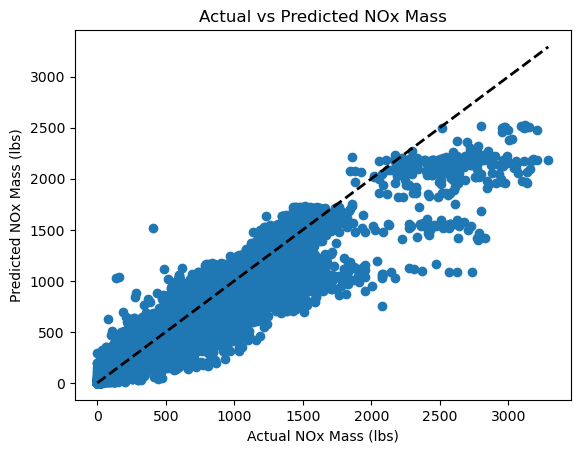

In [ ]:
best_model.save_model("Trained Models/XGB_HPO_TX_NOx_No_Lags.json")

y_pred = best_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=best_avg_iteration)

    y_pred = model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9446, MSE: 2391.3062, RMSE: 48.9010, nRMSE: 0.2354
Train: 2020, Test: 2021 | R^2: 0.9513, MSE: 2274.2991, RMSE: 47.6896, nRMSE: 0.2206
Train: 2021, Test: 2022 | R^2: 0.9483, MSE: 2325.8154, RMSE: 48.2267, nRMSE: 0.2274
Train: 2022, Test: 2023 | R^2: 0.9384, MSE: 2484.6721, RMSE: 49.8465, nRMSE: 0.2482
Train: 2023, Test: 2024 | R^2: 0.9544, MSE: 1942.0880, RMSE: 44.0691, nRMSE: 0.2136


In [36]:
r2_list = [0.9446, 0.9513, 0.9483, 0.9384, 0.9544]
mse_list = [2391.3062, 2274.2991, 2325.8154, 2484.6721, 1942.0880]
rmse_list = [48.9010, 47.6896, 48.2267, 49.8465, 44.0691]
nrmse_list = [0.2354, 0.2206, 0.2274, 0.2482, 0.2136]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9474
Mean MSE: 2283.6362
Mean RMSE: 47.7466
Mean nRMSE: 0.229


In [ ]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=best_avg_iteration)

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")



Train: [2019], Test: 2020 | R^2: 0.9446, MSE: 2391.3062, RMSE: 48.9010, nRMSE: 0.2354
Train: [2019, 2020], Test: 2021 | R^2: 0.9536, MSE: 2168.2341, RMSE: 46.5643, nRMSE: 0.2154
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9529, MSE: 2118.9500, RMSE: 46.0321, nRMSE: 0.2171
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9427, MSE: 2313.0322, RMSE: 48.0940, nRMSE: 0.2394
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9545, MSE: 1936.1322, RMSE: 44.0015, nRMSE: 0.2133


In [37]:
r2_list = [0.9446, 0.9536, 0.9529, 0.9427, 0.9545]
mse_list = [2391.3062, 2168.2341, 2118.9500, 2313.0322, 1936.1322]
rmse_list = [48.9010, 46.5643, 46.0321, 48.0940, 44.0015]
nrmse_list = [0.2354, 0.2154, 0.2171, 0.2394, 0.2133]

print("Mean R2:", round(np.mean(r2_list), 4))
print("Mean MSE:", round(np.mean(mse_list), 4))
print("Mean RMSE:", round(np.mean(rmse_list), 4))
print("Mean nRMSE:", round(np.mean(nrmse_list), 4))

Mean R2: 0.9497
Mean MSE: 2185.5309
Mean RMSE: 46.7186
Mean nRMSE: 0.2241


In [ ]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=best_avg_iteration)

    y_pred = model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2024 | R^2: 0.9021, MSE: 4165.7378, RMSE: 64.5425, nRMSE: 0.3128
Train: [2019, 2020], Test: 2024 | R^2: 0.9077, MSE: 3928.8835, RMSE: 62.6808, nRMSE: 0.3038
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9172, MSE: 3521.5042, RMSE: 59.3423, nRMSE: 0.2876
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9275, MSE: 3084.1643, RMSE: 55.5353, nRMSE: 0.2692
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9545, MSE: 1936.1322, RMSE: 44.0015, nRMSE: 0.2133


In [39]:
r2_list = [0.9021, 0.9077, 0.9172, 0.9275, 0.9545]
mse_list = [4165.7378, 3928.8835, 3521.5042, 3084.1643, 1936.1322]
rmse_list = [64.5425, 62.6808, 59.3423, 55.5353, 44.0015]
nrmse_list = [0.3128, 0.3038, 0.2876, 0.2692, 0.2133]

print("R2:", round(np.mean(r2_list), 4))
print("MSE:", round(np.mean(mse_list), 4))
print("RMSE:", round(np.mean(rmse_list), 4))
print("nRMSE:", round(np.mean(nrmse_list), 4))

R2: 0.9218
MSE: 3327.2844
RMSE: 57.2205
nRMSE: 0.2773


<h2>Visualizations</h2>

- some optuna history plots of NOx optimizations (show value of objective function across studies -> RMSE)

In [26]:
# NY NOx no lags
study = optuna.load_study(
    study_name="30_07_00_20_XGB_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.update_layout(title="Optimization History: NY NOx (No Lags)")
opt_history.show()



In [29]:
study = optuna.load_study(
    study_name="31_07_XX_XX_XGB_NY_NOx_With_Lags",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.update_layout(title="Optimization History: NY NOx (With Lags)")
opt_history.show()

In [27]:
study = optuna.load_study(
    study_name="01_08_00_20_XGB_WY_NOx",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.update_layout(title="Optimization History: WY NOx (No Lags)")
opt_history.show()

In [28]:
# TX NOx no lags
study = optuna.load_study(
    study_name="03_08_18_00_XGB_TX_NOx",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.update_layout(title="Optimization History: TX NOx (No Lags)")
opt_history.show()
